## **I. Import libraries and data**

In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [7]:
hotels = pd.read_excel('data/HotelCustomersDataset.xlsx')
hotels.head(10)

,ID,Nationality,Age,DaysSinceCreation,AverageLeadTime,LodgingRevenue,OtherRevenue,BookingsCanceled,BookingsNoShowed,BookingsCheckedIn,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
0,1,PRT,51.0,150,45,371.0,105.3,1,0,3,...,0,0,0,0,0,0,0,0,0,0
1,2,PRT,NaN,1095,61,280.0,53.0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,3,DEU,31.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,FRA,60.0,1095,93,240.0,60.0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,5,FRA,51.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,6,JPN,54.0,1095,58,230.0,24.0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
6,7,JPN,49.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,8,FRA,32.0,1095,38,535.0,94.0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
8,9,FRA,42.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
9,10,IRL,25.0,1095,96,174.0,69.0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


## **II. Chart**

### 1. Prepare data:

In [11]:
hotels['date'] = pd.to_datetime('2018-12-31') - pd.to_timedelta(hotels['DaysSinceCreation'], unit='D') # from the last day of 2018, subtract the number of days since creation to get the actual date
hotels.head(10)

,ID,Nationality,Age,DaysSinceCreation,AverageLeadTime,LodgingRevenue,OtherRevenue,BookingsCanceled,BookingsNoShowed,BookingsCheckedIn,...,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom,date
0,1,PRT,51.0,150,45,371.0,105.3,1,0,3,...,0,0,0,0,0,0,0,0,0,2018-08-03
1,2,PRT,NaN,1095,61,280.0,53.0,0,0,1,...,0,0,0,0,0,0,0,0,0,2016-01-01
2,3,DEU,31.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,0,0,0,0,0,0,2016-01-01
3,4,FRA,60.0,1095,93,240.0,60.0,0,0,1,...,0,0,0,0,0,0,0,0,0,2016-01-01
4,5,FRA,51.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,0,0,0,0,0,0,2016-01-01
5,6,JPN,54.0,1095,58,230.0,24.0,0,0,1,...,0,0,0,0,0,0,0,0,0,2016-01-01
6,7,JPN,49.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,0,0,0,0,0,0,2016-01-01
7,8,FRA,32.0,1095,38,535.0,94.0,0,0,1,...,0,0,0,1,0,0,0,0,0,2016-01-01
8,9,FRA,42.0,1095,0,0.0,0.0,0,0,0,...,0,0,0,1,0,0,0,0,0,2016-01-01
9,10,IRL,25.0,1095,96,174.0,69.0,0,0,1,...,0,0,0,0,0,0,0,0,0,2016-01-01


In [12]:
daily_revenue = hotels[['date', 'LodgingRevenue', 'OtherRevenue']]
daily_revenue.head()

,date,LodgingRevenue,OtherRevenue
0,2018-08-03,371.0,105.3
1,2016-01-01,280.0,53.0
2,2016-01-01,0.0,0.0
3,2016-01-01,240.0,60.0
4,2016-01-01,0.0,0.0
5,2016-01-01,230.0,24.0
6,2016-01-01,0.0,0.0
7,2016-01-01,535.0,94.0
8,2016-01-01,0.0,0.0
9,2016-01-01,174.0,69.0


### 2. Daily chart

In [13]:
daily_revenue = hotels.groupby('date').agg({'LodgingRevenue': 'sum', 'OtherRevenue': 'sum'})

daily_revenue.head()

,LodgingRevenue,OtherRevenue
date,,
2016-01-01,10591.35,2472.96
2016-01-02,16600.46,11398.50
2016-01-03,13701.23,7978.80
2016-01-04,2896.70,750.98
2016-01-05,13940.15,6580.39


In [15]:
monthly_revenue = daily_revenue.resample('ME').sum()

monthly_revenue.head()

,LodgingRevenue,OtherRevenue
date,,
2016-01-31,124531.34,52190.50
2016-02-29,131689.12,51203.13
2016-03-31,443476.86,127336.11
2016-04-30,500966.80,145228.87
2016-05-31,634200.17,143359.35


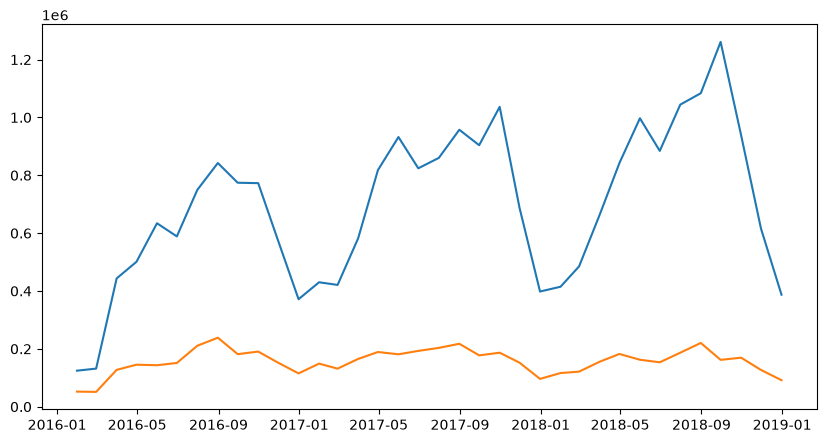

In [17]:
fig, ax = plt.subplots(figsize=(10, 5)) # default configuration is 1x1
ax.plot(monthly_revenue)

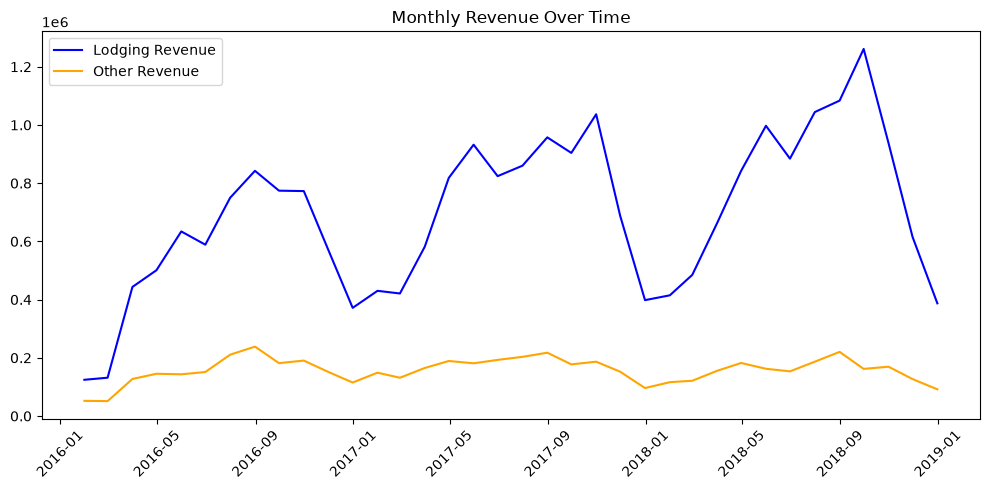

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(monthly_revenue.index, monthly_revenue['LodgingRevenue'], label='Lodging Revenue', color='blue')
ax.plot(monthly_revenue.index, monthly_revenue['OtherRevenue'], label='Other Revenue', color='orange')
ax.legend()

ax.tick_params(axis='x', rotation=45)  # Rotate x-axis labels for better readability
ax.set_title('Monthly Revenue Over Time')
plt.tight_layout()  # Adjust layout to prevent clipping of tick-labels
plt.show()

In [31]:
daily_tracking_booking = hotels.groupby('date').agg({'BookingsCanceled': 'sum', 'BookingsCheckedIn': 'sum', 'BookingsNoShowed': 'sum'})
daily_tracking_booking.head()

,BookingsCanceled,BookingsCheckedIn,BookingsNoShowed
date,,,
2016-01-01,0,51,0
2016-01-02,0,47,0
2016-01-03,0,58,0
2016-01-04,0,10,0
2016-01-05,0,69,2


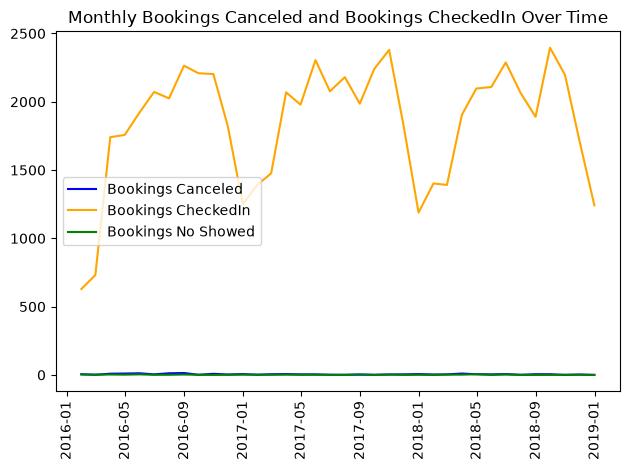

In [32]:
monthly_tracking_booking = daily_tracking_booking.resample('ME').sum()

fig, ax = plt.subplots()

ax.plot(monthly_tracking_booking.index, monthly_tracking_booking['BookingsCanceled'], label='Bookings Canceled', color='blue')
ax.plot(monthly_tracking_booking.index, monthly_tracking_booking['BookingsCheckedIn'], label='Bookings CheckedIn', color='orange')
ax.plot(monthly_tracking_booking.index, monthly_tracking_booking['BookingsNoShowed'], label='Bookings No Showed', color='green')
ax.legend()

ax.tick_params(axis='x', rotation=90)
ax.set_title('Monthly Bookings Canceled and Bookings CheckedIn Over Time')
plt.tight_layout()  # prevent clipping of tick-labels
plt.show()

## **III. Column chart**

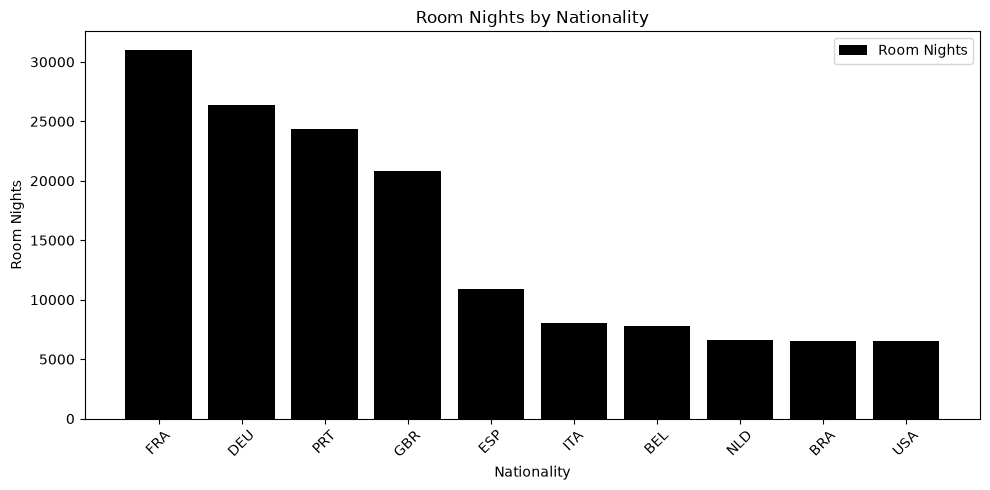

In [47]:
# sum of roomnight by nationality
roomnight_by_nationality = hotels.groupby('Nationality').agg({
  'RoomNights': 'sum',
  'LodgingRevenue': 'sum',
}).sort_values(by='RoomNights', ascending=False).iloc[:10]  # top 10 nationalities by room nights

# bar chart of roomnight by nationality
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(roomnight_by_nationality.index, roomnight_by_nationality['RoomNights'], color='black')
ax.legend(['Room Nights'])
ax.set_title('Room Nights by Nationality')
ax.set_xlabel('Nationality')
ax.set_ylabel('Room Nights')
ax.tick_params(axis='x', rotation=45)  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent clipping of tick-labels
plt.show()

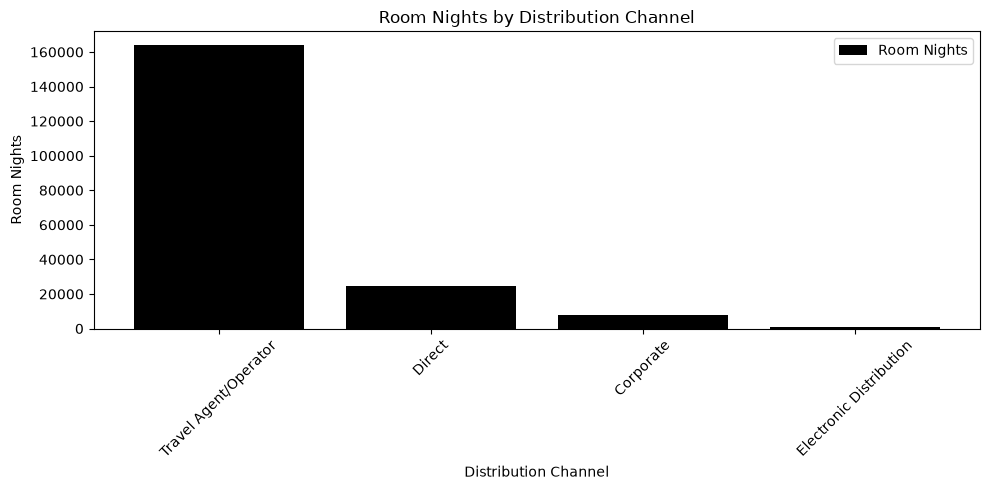

In [48]:
roomnight_by_distribution_channel = hotels.groupby('DistributionChannel').agg({
  'RoomNights': 'sum',
  'LodgingRevenue': 'sum',
}).sort_values(by='RoomNights', ascending=False).iloc[:10]  # top 10 distribution channels by room nights

# bar chart of roomnight by distribution channel
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(roomnight_by_distribution_channel.index, roomnight_by_distribution_channel['RoomNights'], color='black')
ax.legend(['Room Nights'])
ax.set_title('Room Nights by Distribution Channel')
ax.set_xlabel('Distribution Channel')
ax.set_ylabel('Room Nights')
ax.tick_params(axis='x', rotation=45)  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent clipping of tick-labels
plt.show()

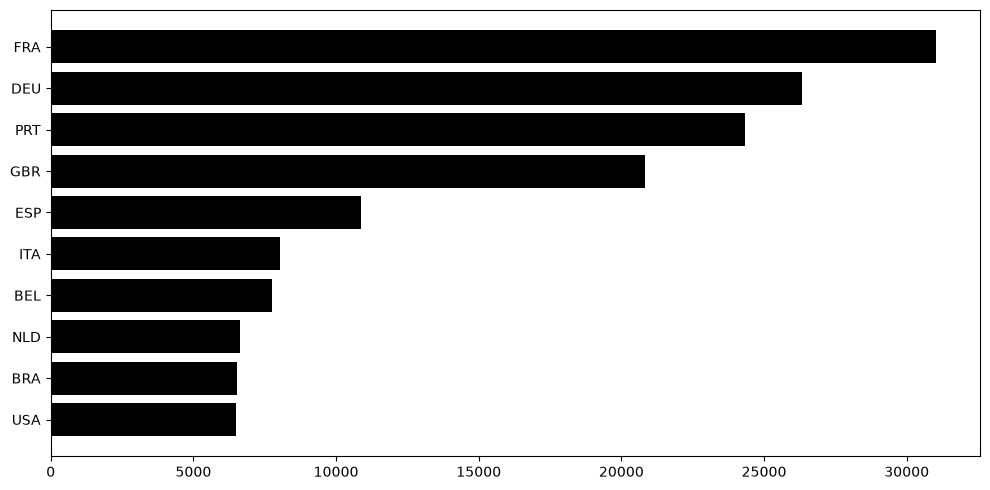

In [51]:
# sum of roomnight by nationality
roomnight_by_nationality = hotels.groupby('Nationality').agg({
  'RoomNights': 'sum',
  'LodgingRevenue': 'sum',
}).sort_values(by='RoomNights', ascending=False).iloc[:10]  # top 10 nationalities by room nights

countries = roomnight_by_nationality.index.tolist()

# bar chart of roomnight by nationality
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(
  countries[::-1],  # reverse the order for better visualization
  roomnight_by_nationality['RoomNights'][::-1],  # reverse the order for better visualization
  color='black'
)

plt.tight_layout()  # Adjust layout to prevent clipping of tick-labels
plt.show()

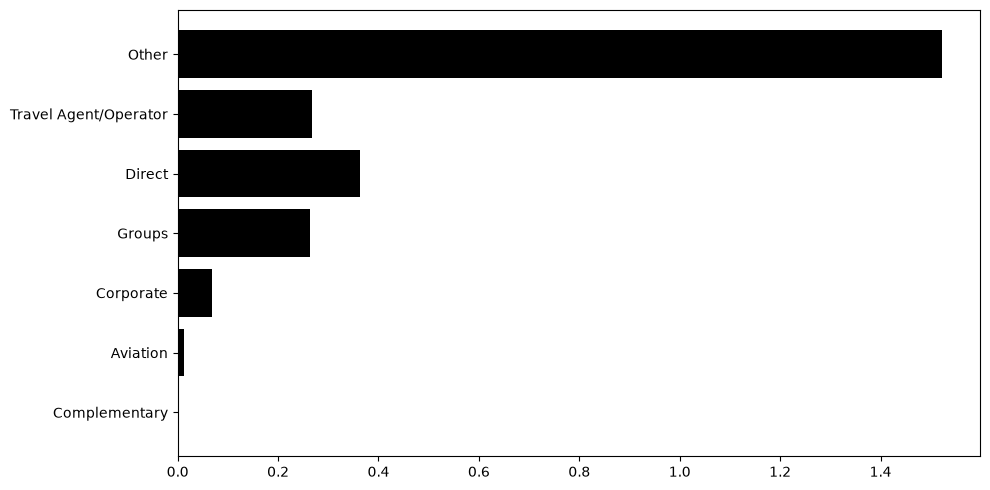

In [57]:

# sum of roomnight by nationality
roomnight_by_nationality = hotels.groupby('MarketSegment').agg({
  'RoomNights': 'sum',
  'LodgingRevenue': 'sum',
}).sort_values(by='RoomNights', ascending=False).iloc[:10]  # top 10 nationalities by room nights

countries = roomnight_by_nationality.index.tolist()

# bar chart of roomnight by nationality
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(
  countries[::-1],  # reverse the order for better visualization
  roomnight_by_nationality['LodgingRevenue'].iloc[::-1] / 10_000_000,  # reverse the order for better visualization
  color='black'
)

plt.tight_layout()  # Adjust layout to prevent clipping of tick-labels
plt.show()

### **IV. Pie chart**

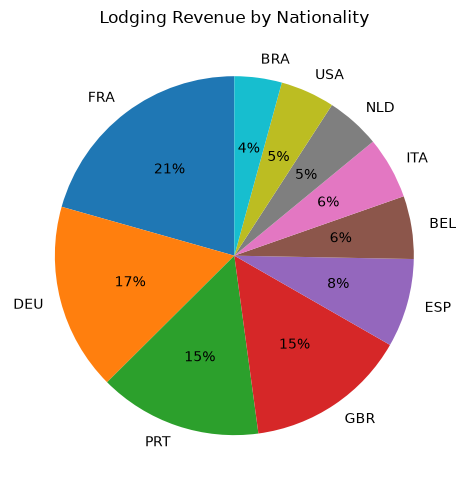

In [66]:
grouping_contries = hotels.groupby('Nationality').agg({
  'LodgingRevenue': 'sum'
}).sort_values(by='LodgingRevenue', ascending=False).iloc[:10]  # top 10 nationalities by lodging revenue
lambda_contries = grouping_contries.apply(lambda x: x * 100 / sum(x)).iloc[0: 10]  # convert to series

# pie chart of lodging revenue by nationality
fig, ax = plt.subplots(figsize=(10, 5))
ax.pie(
  lambda_contries['LodgingRevenue'],
  labels=lambda_contries.index,
  autopct='%.0f%%',
  startangle=90
)
ax.set_title('Lodging Revenue by Nationality')
plt.tight_layout()  # Adjust layout to prevent clipping of tick-labels
plt.show()

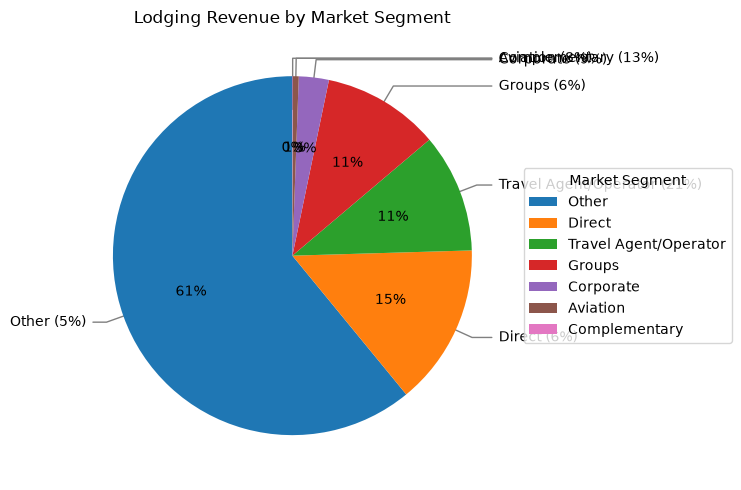

In [84]:
market_segment = hotels.groupby('MarketSegment').agg({
  'LodgingRevenue': 'sum'
}).sort_values(by='LodgingRevenue', ascending=False).iloc[:10]  # top 10 market segments by lodging revenue
lambda_market_segment = market_segment.apply(lambda x: x * 100 / sum(x)).iloc[0: 10]  # convert to series

# pie chart of lodging revenue by market segment
fig, ax = plt.subplots(figsize=(20, 5))
wedges, texts, autotexts = ax.pie(
  lambda_market_segment['LodgingRevenue'],
  # labels=lambda_market_segment.index,
  autopct='%.0f%%',
  startangle=90
)
ax.legend(lambda_market_segment.index, title='Market Segment', loc='center left', bbox_to_anchor=(1, 0, 0.5, 1))

# Styling for the bent leader lines
bbox_props = dict(boxstyle="square,pad=0.3", fc="w", ec="none", alpha=0.0)
kw = dict(
    arrowprops=dict(arrowstyle="-", color="gray", lw=1),
    bbox=bbox_props,
    zorder=0,
    va="center"
)

for i, p in enumerate(wedges):
    # Calculate the midpoint angle of the slice
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))

    # Align text left or right depending on which side of the pie it sits on
    horizontalalignment = {-1: "right", 1: "left"}[int(np.sign(x))]

    # Create a bent line: angled from slice edge, then horizontal to the text
    connectionstyle = f"angle,angleA=0,angleB={ang}"
    kw["arrowprops"].update({"connectionstyle": connectionstyle})

    # Place label outside the pie (1.15 * radius)
    ax.annotate(
        f"{lambda_market_segment.index[i]} ({len(lambda_market_segment.index[i])}%)",
        xy=(0.8 * x, 0.8 * y),          # Point on the outer edge of the slice
        xytext=(1.15 * np.sign(x), 1.1 * y),  # Position of the label text
        horizontalalignment=horizontalalignment,
        **kw
    )

ax.set_title('Lodging Revenue by Market Segment')
plt.tight_layout()  # Adjust layout to prevent clipping of tick-labels
plt.show()